# 6. Zusammenhalt des Netzwerks

Was hält das Netz der Schwimmer zusammen? Grundlage ist das Arbeitsnetz aus Kapitel 4 (Athletenprojektion mit `weight >= 2`). Wir beschreiben zuerst seine Kennzahlen und prüfen mit dem bipartiten Configuration Model, ob die wiederholten Begegnungen zufällig entstehen. Danach testen wir die Robustheit gegenüber dem Entfernen von Athleten und von Veranstaltungstagen und vergleichen die Generationen C1 bis C4 aus Kapitel 5.

Balance entfällt, da das Netz keine positiven und negativen Kanten kennt. Die Node Connectivity ist wegen der Cut-Vertices trivial 1.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
NETWORK_DIR = PROJECT_ROOT / 'data/processed/networks'
CENTRALITY_DIR = PROJECT_ROOT / 'data/processed/centrality'
RESULT_DIR = PROJECT_ROOT / 'data/processed/zusammenhalt'
REPORT_DIR = PROJECT_ROOT / 'Report/graphics'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

WORK_THRESHOLD = 2
SEED = 42
N_NULL = 100
N_RANDOM_ORDERS = 10
ATHLETE_SHARES = np.linspace(0, 0.10, 11)
PARTICIPATION_SHARES = np.linspace(0, 0.30, 13)
COLOR, ORANGE, MUTED = '#367da2', '#eb6834', '#a3a29d'
REPORT_RC = {'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
             'xtick.labelsize': 7, 'ytick.labelsize': 7, 'pdf.fonttype': 42}
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'axes.edgecolor': '#52514e',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
})

## 6.1 Daten und Projektion

Für Nullmodell und Robustheit muss die Projektion oft neu gebildet werden. Wir berechnen sie deshalb direkt aus der Zuordnung Athlet ↔ Veranstaltungstag: Jeder Tag verbindet alle Paare seiner Athleten, das Gewicht zählt die gemeinsamen Tage, behalten werden Paare mit mindestens zwei Tagen. Die Funktion wird gegen das gespeicherte Arbeitsnetz geprüft.

In [2]:
G = nx.read_gexf(NETWORK_DIR / 'athletes.gexf')
nodes = sorted(G)
node_index = {node: i for i, node in enumerate(nodes)}
N = len(nodes)
athletes = pd.DataFrame.from_dict(dict(G.nodes(data=True)), orient='index').loc[nodes]

participations = pd.read_parquet(NETWORK_DIR / 'athlete_events.parquet',
                                 columns=['athlete_node', 'event_id', 'best_name'])
participations['a'] = participations['athlete_node'].map(node_index)
assert participations['a'].notna().all() and not participations.duplicated(['a', 'event_id']).any()
day_size = participations.groupby('event_id').size()
day_nations = (participations.assign(nation=participations['athlete_node'].map(athletes['athlete_nation']))
               .groupby('event_id')['nation'].nunique())


def project(rows, threshold=WORK_THRESHOLD):
    """Athletenprojektion mit Mindestgewicht aus Zeilen (a, event_id) bilden."""
    rows = rows.sort_values(['event_id', 'a'])
    codes = rows['a'].to_numpy()
    bounds = np.flatnonzero(np.diff(pd.factorize(rows['event_id'])[0])) + 1
    left, right = [], []
    for members in np.split(codes, bounds):
        if len(members) > 1:
            i, j = np.triu_indices(len(members), 1)
            left.append(members[i])
            right.append(members[j])
    keys = np.concatenate(left).astype(np.int64) * N + np.concatenate(right)
    pairs, counts = np.unique(keys, return_counts=True)
    pairs = pairs[counts >= threshold]
    graph = nx.Graph()
    graph.add_nodes_from(range(N))
    graph.add_edges_from(zip((pairs // N).tolist(), (pairs % N).tolist()))
    return graph


def giant_share(graph):
    return len(max(nx.connected_components(graph), key=len)) / N


W = project(participations[['a', 'event_id']])
reference = {tuple(sorted((node_index[u], node_index[v])))
             for u, v, w in G.edges(data='weight') if w >= WORK_THRESHOLD}
assert {tuple(sorted(e)) for e in W.edges()} == reference
print(f"Arbeitsnetz neu projiziert: {W.number_of_nodes():_} Athleten, {W.number_of_edges():_} Kanten".replace('_', "'"))

Arbeitsnetz neu projiziert: 13'156 Athleten, 357'219 Kanten


## 6.2 Kennzahlen des Arbeitsnetzes

Density und Clustering wie im Skript (Clustering als Mittel der lokalen Koeffizienten). Diameter und Betweenness-Zentralisierung beziehen sich auf die Giant Component. Die Zentralisierungen folgen Freeman: Degree mit $\sum (k^* - k_i) / ((n-1)(n-2))$, Betweenness mit den normierten Werten und $\sum (b^* - b_i) / (n-1)$.

In [3]:
giant = W.subgraph(max(nx.connected_components(W), key=len)).copy()
degrees = np.array([d for _, d in W.degree()])
actors = pd.read_parquet(CENTRALITY_DIR / 'actor_centralities.parquet')
betweenness = actors['betweenness'].dropna()
assert len(betweenness) == giant.number_of_nodes()

metrics = pd.Series({
    'Athleten': N,
    'Kanten': W.number_of_edges(),
    'Density': nx.density(W),
    'Clustering': nx.average_clustering(W),
    'Anteil Giant Component': giant_share(W),
    'Diameter (Giant Component)': nx.diameter(giant, usebounds=True),
    'Degree-Zentralisierung': (degrees.max() - degrees).sum() / ((N - 1) * (N - 2)),
    'Betweenness-Zentralisierung': (betweenness.max() - betweenness).sum() / (len(betweenness) - 1),
}, name='Arbeitsnetz')
display(metrics.map(lambda value: f"{value:,.0f}".replace(',', "'") if value >= 10 else f'{value:.4f}').to_frame())

,Arbeitsnetz
Athleten,13'156
Kanten,357'219
Density,0.0041
Clustering,0.4886
Anteil Giant Component,0.9660
Diameter (Giant Component),11
Degree-Zentralisierung,0.0372
Betweenness-Zentralisierung,0.0185


### Cut-Vertices und Bridges

Ein Cut-Vertex trennt beim Entfernen Teile von der Giant Component ab. Für jeden Cut-Vertex zählen wir, wie viele Athleten nur über ihn angebunden sind, und aus welchen Nationen diese stammen.

In [4]:
cut_vertices = list(nx.articulation_points(giant))
bridges = list(nx.bridges(giant))
rows = []
for vertex in cut_vertices:
    rest = giant.subgraph(set(giant) - {vertex})
    parts = sorted(nx.connected_components(rest), key=len, reverse=True)[1:]
    detached = [nodes[i] for part in parts for i in part]
    rows.append({
        'athlete': nodes[vertex],
        'name': athletes.loc[nodes[vertex], 'athlete_name'],
        'nation': athletes.loc[nodes[vertex], 'athlete_nation'],
        'detached': len(detached),
        'detached_same_nation': athletes.loc[detached, 'athlete_nation']
                                .eq(athletes.loc[nodes[vertex], 'athlete_nation']).mean(),
    })
cut_profile = pd.DataFrame(rows).sort_values('detached', ascending=False)
print(f'{len(cut_vertices)} Cut-Vertices, {len(bridges)} Bridges in der Giant Component.')
print(f"Abgetrennte Athleten je Cut-Vertex: Median {cut_profile['detached'].median():.0f}, "
      f"Maximum {cut_profile['detached'].max()}")
print(f"Anteil abgetrennter Athleten aus der Nation des Cut-Vertex: "
      f"{(cut_profile['detached'] * cut_profile['detached_same_nation']).sum() / cut_profile['detached'].sum():.0%}")
display(cut_profile.head(8))
display(cut_profile['nation'].value_counts().head(8).rename('Cut-Vertices').to_frame())

184 Cut-Vertices, 182 Bridges in der Giant Component.
Abgetrennte Athleten je Cut-Vertex: Median 1, Maximum 3
Anteil abgetrennter Athleten aus der Nation des Cut-Vertex: 42%


,athlete,name,nation,detached,detached_same_nation
147,athlete_4062507,"LAKHLIFIA, Slimane",Morocco,3,0.0
120,athlete_4237131,"DINGJAN, Merindah",Australia,3,0.0
95,athlete_4772211,"JUNG, Won Yong",Korea,2,1.0
108,athlete_4798336,"BAR-OR, Nimrod S",Israel,2,0.5
129,athlete_4201687,"LYAZEVA, Anastasia",Russia,2,0.0
43,athlete_5540343,"RAFI, Samiul Islam",Bangladesh,2,0.0
146,athlete_4063604,"ABDEL-RAOUF, Aymen",Egypt,2,1.0
126,athlete_4202981,"GONZALEZ, Fernanda",Mexico,2,0.0


,Cut-Vertices
nation,
Mexico,10
Japan,9
Argentina,7
United Arab Emirates,5
Hong Kong,5
Thailand,5
Greece,5
Korea,4


## 6.3 Nullmodell: bipartites Configuration Model

Das gewöhnliche Configuration Model aus dem Skript mischt die Kanten der Projektion und zerstört dabei die Dreiecke, die jeder Veranstaltungstag erzeugt. Für eine Projektion ist es deshalb kein fairer Vergleich. Wir wenden das Configuration Model stattdessen auf das Two-Mode-Netz an (bipartites Configuration Model) und projizieren erst danach:

- H0: Die Struktur des Arbeitsnetzes entsteht allein aus der Grösse der Veranstaltungstage und der Zahl der Tage pro Athlet. H1: Athleten begegnen sich häufiger wiederholt als dadurch erklärt.
- Referenz-Netzwerke: 100-mal werden die Athleten zufällig auf die Teilnahmen verteilt. Jeder Tag behält seine Grösse, jeder Athlet seine Zahl an Tagen. Die Zahl der Begegnungen bleibt damit gleich, nur ihre Verteilung auf Athletenpaare ist zufällig. Doppelte Zuordnungen eines Athleten zum selben Tag (selten) werden entfernt. Danach wird wie im Original projiziert und auf Gewicht ≥ 2 gefiltert.
- Teststatistiken: Zahl der Kanten, Clustering und Anteil der Giant Component. α = 0.05.

In [5]:
rng = np.random.default_rng(SEED)
null_rows = []
for _ in range(N_NULL):
    shuffled = participations[['a', 'event_id']].assign(a=rng.permutation(participations['a'].to_numpy()))
    graph = project(shuffled.drop_duplicates())
    null_rows.append({'Kanten': graph.number_of_edges(),
                      'Clustering': nx.average_clustering(graph),
                      'Anteil Giant Component': giant_share(graph)})
null_model = pd.DataFrame(null_rows)

null_summary = pd.DataFrame({
    'Arbeitsnetz': metrics[['Kanten', 'Clustering', 'Anteil Giant Component']],
    'Nullmodell (Mittel)': null_model.mean(),
    'Nullmodell (Maximum)': null_model.max(),
    'p-Wert': [(null_model[c] >= metrics[c]).mean() for c in null_model.columns],
})
null_summary['p-Wert'] = null_summary['p-Wert'].map(lambda p: f'< {1 / N_NULL:.2f}' if p == 0 else f'{p:.2f}')
display(null_summary)

,Arbeitsnetz,Nullmodell (Mittel),Nullmodell (Maximum),p-Wert
Kanten,357219.000000,35929.560000,36692.000000,< 0.01
Clustering,0.488646,0.036845,0.039399,< 0.01
Anteil Giant Component,0.966023,0.657205,0.666464,< 0.01


Das Arbeitsnetz hat rund zehnmal so viele Kanten wie die Referenz-Netzwerke (357'219 gegenüber im Mittel 35'930), ein Clustering von 0.49 statt 0.04 und eine Giant Component mit 96.6 % statt 66 % der Athleten. Keines der 100 Referenz-Netzwerke erreicht einen der beobachteten Werte (p < 0.01). Wiederholte Begegnungen sind also kein Zufall. Dieselben Athleten treffen sich immer wieder, etwa an nationalen Meisterschaften und regelmässigen internationalen Wettkämpfen. Das passt zu den nationalen Communities aus Kapitel 5.

## 6.4 Robustheit

Wir entfernen schrittweise Athleten oder Veranstaltungstage und messen den Anteil aller Athleten in der Giant Component.

- **Athleten:** in absteigender Reihenfolge der Betweenness (Kapitel 6) oder des Degree, oder zufällig (10 Reihenfolgen). Athleten ausserhalb der Giant Component haben keine Betweenness und kommen bei dieser Reihenfolge zuletzt.
- **Veranstaltungstage:** nach Internationalität (Zahl der Nationen am Tag, bei Gleichstand nach Grösse), nach Grösse oder zufällig (10 Reihenfolgen). Damit der Vergleich fair ist, zeigen wir den Anteil entfernter Teilnahmen, nicht die Zahl entfernter Tage. Nach jedem Schritt wird neu projiziert.

In [6]:
def remove_athletes(order):
    out = []
    for share in ATHLETE_SHARES:
        removed = {node_index[n] for n in order[:round(share * N)]}
        out.append(giant_share(W.subgraph(set(W) - removed)))
    return out


degree_order = pd.Series(dict(G.degree())).loc[nodes].sort_values(ascending=False, kind='stable').index
betweenness_order = actors['betweenness'].reindex(nodes).fillna(-1).sort_values(ascending=False, kind='stable').index
athlete_curves = pd.DataFrame({
    'Betweenness': remove_athletes(betweenness_order),
    'Degree': remove_athletes(degree_order),
}, index=ATHLETE_SHARES)
random_athletes = np.array([remove_athletes(pd.Index(rng.permutation(nodes))) for _ in range(N_RANDOM_ORDERS)])
athlete_curves['Zufall'] = random_athletes.mean(axis=0)
athlete_curves['Zufall min'] = random_athletes.min(axis=0)
athlete_curves['Zufall max'] = random_athletes.max(axis=0)
display(athlete_curves.round(3))

,Betweenness,Degree,Zufall,Zufall min,Zufall max
0.00,0.966,0.966,0.966,0.966,0.966
0.01,0.956,0.956,0.956,0.956,0.957
0.02,0.946,0.946,0.947,0.946,0.947
0.03,0.935,0.935,0.937,0.936,0.938
0.04,0.925,0.925,0.927,0.927,0.928
0.05,0.912,0.915,0.917,0.917,0.918
0.06,0.902,0.904,0.907,0.907,0.908
0.07,0.892,0.894,0.897,0.897,0.898
0.08,0.881,0.884,0.888,0.887,0.888
0.09,0.871,0.873,0.878,0.877,0.879


In [7]:
total_participations = len(participations)


def remove_days(order):
    cumulative = day_size.loc[order].cumsum()
    giant_shares, edge_shares = [], []
    for share in PARTICIPATION_SHARES:
        dropped = order[cumulative.to_numpy() <= share * total_participations]
        graph = project(participations.loc[~participations['event_id'].isin(dropped), ['a', 'event_id']])
        giant_shares.append(giant_share(graph))
        edge_shares.append(graph.number_of_edges() / W.number_of_edges())
    return giant_shares, edge_shares


day_table = pd.DataFrame({'nations': day_nations, 'size': day_size})
orders = {
    'International': day_table.sort_values(['nations', 'size'], ascending=False, kind='stable').index,
    'Grösse': day_table.sort_values(['size', 'nations'], ascending=False, kind='stable').index,
}
day_giant, day_edges = {}, {}
for label, order in orders.items():
    day_giant[label], day_edges[label] = remove_days(order)
random_days = [remove_days(pd.Index(rng.permutation(day_table.index))) for _ in range(N_RANDOM_ORDERS)]
random_giant = np.array([g for g, _ in random_days])
random_edges = np.array([e for _, e in random_days])
day_curves = pd.DataFrame(day_giant, index=PARTICIPATION_SHARES).assign(
    Zufall=random_giant.mean(axis=0), **{'Zufall min': random_giant.min(axis=0),
                                         'Zufall max': random_giant.max(axis=0)})
edge_curves = pd.DataFrame(day_edges, index=PARTICIPATION_SHARES).assign(Zufall=random_edges.mean(axis=0))
display(day_curves.round(3))
display(edge_curves.round(3).rename(columns=lambda c: f'Kanten {c}'))

top_days = day_table.sort_values(['nations', 'size'], ascending=False).head(5).join(
    participations.drop_duplicates('event_id').set_index('event_id')['best_name'])
display(top_days)

,International,Grösse,Zufall,Zufall min,Zufall max
0.000,0.966,0.966,0.966,0.966,0.966
0.025,0.960,0.960,0.963,0.962,0.964
0.050,0.938,0.947,0.961,0.958,0.962
0.075,0.911,0.916,0.957,0.955,0.959
0.100,0.882,0.878,0.954,0.951,0.957
0.125,0.844,0.854,0.950,0.946,0.953
0.150,0.810,0.825,0.946,0.941,0.950
0.175,0.776,0.804,0.941,0.938,0.945
0.200,0.743,0.789,0.936,0.932,0.940
0.225,0.707,0.773,0.930,0.926,0.934


,Kanten International,Kanten Grösse,Kanten Zufall
0.000,1.000,1.000,1.000
0.025,0.723,0.711,0.974
0.050,0.621,0.606,0.942
0.075,0.555,0.535,0.913
0.100,0.516,0.488,0.883
0.125,0.487,0.445,0.851
0.150,0.460,0.407,0.812
0.175,0.440,0.371,0.781
0.200,0.427,0.336,0.748
0.225,0.409,0.304,0.716


,nations,size,best_name
event_id,,,
event_23339,105,287,FINA: 13th World Championships
event_23344,98,241,FINA: 13th World Championships
event_59730,98,240,World Aquatics Championships
event_23326,92,189,FINA: 12th World Short Course ...
event_23328,90,175,FINA: 12th World Short Course ...


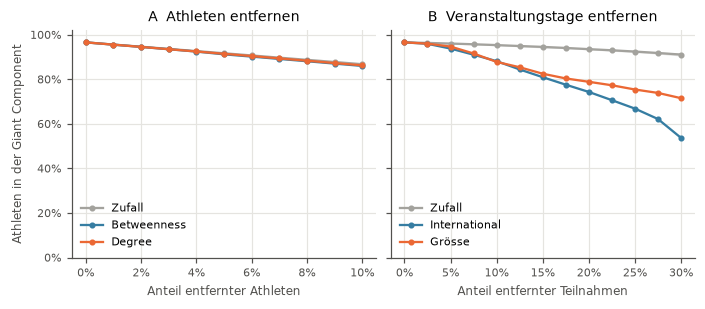

In [8]:
with plt.rc_context(REPORT_RC):
    fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.7), layout='constrained', sharey=True)
    panels = [
        (axes[0], athlete_curves, 'Anteil entfernter Athleten',
         'A  Athleten entfernen', [('Betweenness', COLOR), ('Degree', ORANGE)]),
        (axes[1], day_curves, 'Anteil entfernter Teilnahmen',
         'B  Veranstaltungstage entfernen', [('International', COLOR), ('Grösse', ORANGE)]),
    ]
    for ax, curves, xlabel, title, series in panels:
        ax.fill_between(curves.index, curves['Zufall min'], curves['Zufall max'], color=MUTED, alpha=0.3,
                        linewidth=0)
        ax.plot(curves.index, curves['Zufall'], color=MUTED, marker='o', markersize=3, label='Zufall')
        for column, color in series:
            ax.plot(curves.index, curves[column], color=color, marker='o', markersize=3, label=column)
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        ax.set(title=title, xlabel=xlabel)
        ax.legend(frameon=False, fontsize=7, loc='lower left')
    axes[0].set(ylabel='Athleten in der Giant Component', ylim=(0, 1.02))
    fig.savefig(REPORT_DIR / '07_robustheit.pdf', bbox_inches='tight')
    plt.show()

Das Entfernen einzelner Athleten schadet dem Netz kaum. Auch ohne die 10 % mit der höchsten Betweenness oder dem höchsten Degree sinkt der Anteil in der Giant Component nur auf 86.0 bzw. 86.3 %, praktisch gleich wie bei zufällig entfernten Athleten (86.8 %). Verloren gehen fast nur die entfernten Athleten selbst. Die 184 Cut-Vertices trennen jeweils höchstens drei Athleten ab (Median 1) und liegen damit am Rand des Netzes.

Ganz anders bei den Veranstaltungstagen. Fehlen die internationalsten Tage, bis 30 % der Teilnahmen entfernt sind, bleiben nur 53.7 % der Athleten in der Giant Component, bei zufälligen Tagen 91.1 %. Das Entfernen der grössten Tage löscht zwar mehr Kanten (es bleiben 22 % statt 36 %), zerlegt das Netz aber weniger (71.5 %). Entscheidend ist also nicht die Grösse eines Tages, sondern dass er Athleten vieler Nationen zusammenbringt. Internationale Meisterschaften wie die WM 2009 in Rom mit 105 Nationen an einem Tag halten das Netz zusammen.

## 6.5 Generationen im Vergleich

Die vier Generationen aus Kapitel 5 erlauben einen zeitlichen Vergleich. Für jede Generation betrachten wir das Teilnetz ihrer Athleten im Arbeitsnetz. Die Density hängt von der Grösse ab und ist zwischen verschieden grossen Teilnetzen nur vorsichtig vergleichbar.

In [9]:
communities = pd.read_parquet(NETWORK_DIR / 'athlete_communities.parquet').set_index('node')['louvain']
generation_rows = {}
for label in ['C4', 'C2', 'C3', 'C1']:
    members = [node_index[n] for n in communities.index[communities.eq(label)]]
    sub = W.subgraph(members)
    sub_giant = sub.subgraph(max(nx.connected_components(sub), key=len))
    sub_degrees = np.array([d for _, d in sub.degree()])
    n = len(sub)
    generation_rows[label] = {
        'Athleten': n,
        'Median Jahrgang': athletes.loc[[nodes[i] for i in members], 'birth_year'].median(),
        'Kanten': sub.number_of_edges(),
        'Density': nx.density(sub),
        'Mittlerer Grad': 2 * sub.number_of_edges() / n,
        'Clustering': nx.average_clustering(sub),
        'Diameter': nx.diameter(sub_giant, usebounds=True),
        'Degree-Zentralisierung': (sub_degrees.max() - sub_degrees).sum() / ((n - 1) * (n - 2)),
    }
generations = pd.DataFrame(generation_rows).T
display(generations.round(3))

,Athleten,Median Jahrgang,Kanten,Density,Mittlerer Grad,Clustering,Diameter,Degree-Zentralisierung
C4,1175.0,1978.0,16375.0,0.024,27.872,0.521,9.0,0.112
C2,1881.0,1988.0,63652.0,0.036,67.679,0.531,7.0,0.214
C3,1304.0,1996.0,34501.0,0.041,52.916,0.603,7.0,0.230
C1,2064.0,2002.0,51669.0,0.024,50.067,0.540,7.0,0.180


### Zeitliche Lage und zentrale Athleten

Zur Deutung der Unterschiede prüfen wir, wann die Teilnahmen jeder Generation liegen und wie viele Veranstaltungstage ein Athlet im Median hat. Alle Anteile beziehen sich auf Teilnahmen (Athlet an Veranstaltungstag), auch der Vergleichswert für den ganzen Datensatz. Dazu zeigen wir die drei Athleten mit dem höchsten Degree im Teilnetz jeder Generation.

In [10]:
dates = pd.read_parquet(NETWORK_DIR / 'athlete_events.parquet', columns=['athlete_node', 'event_id', 'best_date'])
dates['year'] = pd.to_datetime(dates['best_date']).dt.year
dates['generation'] = dates['athlete_node'].map(communities)


def era_profile(rows):
    return {
        'Teilnahmen': len(rows),
        'Anteil vor 2005': (rows['year'] < 2005).mean(),
        'Anteil 2008/09': rows['year'].between(2008, 2009).mean(),
        'Tage pro Athlet (Median)': rows.groupby('athlete_node')['event_id'].nunique().median(),
    }


era = pd.DataFrame({label: era_profile(dates[dates['generation'].eq(label)]) for label in ['C4', 'C2', 'C3', 'C1']}
                   | {'Alle': era_profile(dates)}).T
era_display = era.astype(object)
for column in ['Anteil vor 2005', 'Anteil 2008/09']:
    era_display[column] = era[column].map('{:.1%}'.format)
display(era_display)

top_rows = []
for label in ['C4', 'C2', 'C3', 'C1']:
    sub = W.subgraph([node_index[n] for n in communities.index[communities.eq(label)]])
    for i, degree in sorted(sub.degree(), key=lambda item: (-item[1], item[0]))[:3]:
        top_rows.append({'Generation': label, 'Athlet': athletes.loc[nodes[i], 'athlete_name'],
                         'Nation': athletes.loc[nodes[i], 'athlete_nation'], 'Degree im Teilnetz': degree})
display(pd.DataFrame(top_rows))

,Teilnahmen,Anteil vor 2005,Anteil 2008/09,Tage pro Athlet (Median)
C4,9823.0,77.3%,4.4%,7.0
C2,29481.0,8.7%,31.9%,13.0
C3,15030.0,0.4%,4.7%,9.0
C1,29425.0,0.1%,1.7%,11.0
Alle,238942.0,5.0%,8.4%,16.0


,Generation,Athlet,Nation,Degree im Teilnetz
0,C4,"KUANG, Chia-Hsien",Chinese Taipei,159
1,C4,"CHAY, Jung Jun Mark",Singapore,146
2,C4,"ROBERTS, Kenny",Seychelles,142
3,C2,"TING, Sheng-Yo",Chinese Taipei,470
4,C2,"DUDA, Andrejs",Latvia,432
5,C2,"BEAHAN, Grant",Zimbabwe,407
6,C3,"BLAZHEVSKI, Marko",North Macedonia,352
7,C3,"MENA, Miguel Angel",Nicaragua,310
8,C3,"NGUI, Axel Toni Steven",Philippines,308
9,C1,"KNOX, Finlay",Canada,421


Die Generation mit Jahrgang 1988 (C2) ist am dichtesten vernetzt. Ein Drittel ihrer Teilnahmen fällt in die Jahre 2008 und 2009, in denen der Datensatz bereits in Kapitel 2 einen Anstieg zeigt. Ihre Bestleistungen konzentrieren sich auf wenige Saisons und dieselben Meisterschaften, allen voran die WM 2009 in Rom. Die zentralsten Athleten von C2 sind dieselben wie an der Eigenvector-Spitze in Kapitel 6. Auch in C3 prägen Athleten kleinerer Nationen die Spitze. Wenige Athleten, die an vielen grossen Meisterschaften starten, erklären so die höhere Zentralisierung dieser beiden Generationen.

Die älteste Generation C4 ist am losesten verbunden. Der Grossteil ihrer Teilnahmen liegt vor 2005, im gesamten Datensatz nur ein kleiner Teil. Ein Athlet von C4 hat im Median deutlich weniger gespeicherte Veranstaltungstage als in C2. Die geringe Vernetzung von C4 spiegelt deshalb vor allem, dass ältere Bestleistungen seltener erfasst sind. Das Clustering ist in allen Generationen ähnlich hoch, da es vor allem aus der Projektion entsteht.

## 6.6 Export

In [11]:
metrics.to_frame().to_parquet(RESULT_DIR / 'kennzahlen.parquet')
null_model.to_parquet(RESULT_DIR / 'nullmodell.parquet')
cut_profile.to_parquet(RESULT_DIR / 'cut_vertices.parquet', index=False)
athlete_curves.to_parquet(RESULT_DIR / 'robustheit_athleten.parquet')
day_curves.join(edge_curves.add_prefix('Kanten ')).to_parquet(RESULT_DIR / 'robustheit_tage.parquet')
generations.to_parquet(RESULT_DIR / 'generationen.parquet')
print('Gespeichert in', RESULT_DIR.relative_to(PROJECT_ROOT))

Gespeichert in data/processed/zusammenhalt
